In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=350)

df = pd.concat(
    [data.data.features, data.data.targets], axis=1
)

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
print("Shape:", df.shape)
print(df.info())
print(df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (30000, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int

In [ ]:
# The UCI ML Repository uses 'Y' as the default target variable
target = "Y"

# Check the target distribution and default rate using the correct column
print(df[target].value_counts())
print("Default rate:", round(df[target].mean() * 100, 2), "%")

Y
0    23364
1     6636
Name: count, dtype: int64
Default rate: 22.12 %


            Default Rate (%)  count
LIMIT_BAND                         
0-50k              31.787389   7676
50k-100k           25.798424   4822
100k-200k          19.479695   7880
200k-500k          14.804588   9416
500k+              11.165049    206


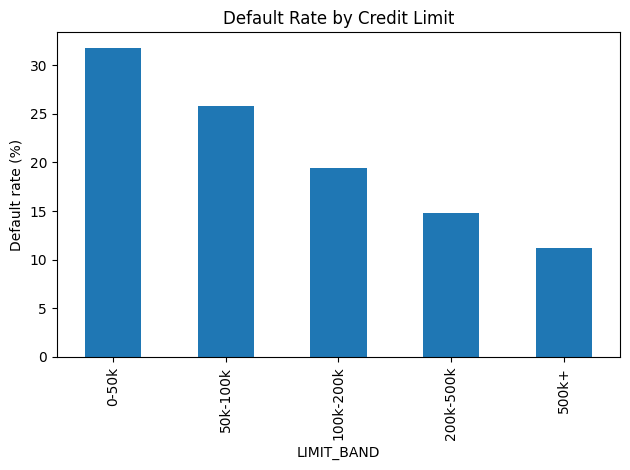

In [ ]:
df["LIMIT_BAND"] = pd.cut(
    df["X1"],
    bins=[0, 50000, 100000, 200000, 500000, np.inf],
    labels=["0-50k", "50k-100k", "100k-200k",
            "200k-500k", "500k+"]
)

credit_risk = df.groupby(
    "LIMIT_BAND", observed=True
)["Y"].agg(["mean", "count"])

credit_risk["mean"] *= 100
credit_risk = credit_risk.rename(
    columns={"mean": "Default Rate (%)"}
)

print(credit_risk)

credit_risk["Default Rate (%)"].plot(
    kind="bar", ylabel="Default rate (%)",
    title="Default Rate by Credit Limit"
)
plt.tight_layout()
plt.show()

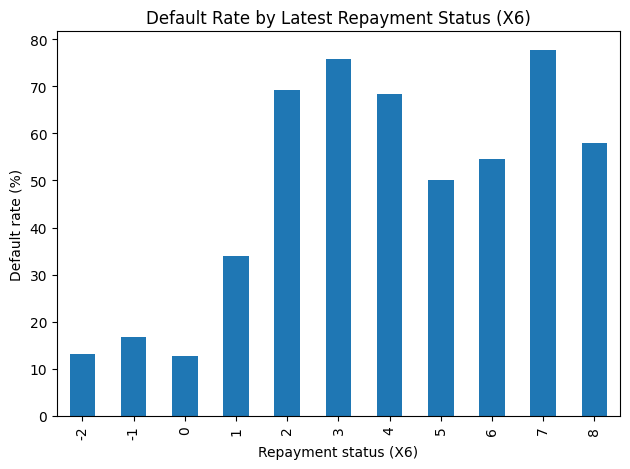

In [ ]:
# Map generic column names to repayment history
# X6 is the repayment status in September, 2005 (equivalent to PAY_1)
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

df.groupby("X6")["Y"].mean().mul(100).plot(
    kind="bar",
    title="Default Rate by Latest Repayment Status (X6)",
    xlabel="Repayment status (X6)",
    ylabel="Default rate (%)"
)
plt.tight_layout()
plt.show()

In [ ]:
for col in pay_cols:
    print(f"\n{col}")
    print(
        df.groupby(col, observed=True)["Y"]
          .agg(["mean", "count"])
          .assign(default_rate_pct=lambda x: x["mean"] * 100)
          .round(3)
    )


X6
     mean  count  default_rate_pct
X6                                
-2  0.132   2759            13.229
-1  0.168   5686            16.778
 0  0.128  14737            12.811
 1  0.339   3688            33.948
 2  0.691   2667            69.141
 3  0.758    322            75.776
 4  0.684     76            68.421
 5  0.500     26            50.000
 6  0.545     11            54.545
 7  0.778      9            77.778
 8  0.579     19            57.895

X7
     mean  count  default_rate_pct
X7                                
-2  0.183   3782            18.271
-1  0.160   6050            15.967
 0  0.159  15730            15.912
 1  0.179     28            17.857
 2  0.556   3927            55.615
 3  0.617    326            61.656
 4  0.505     99            50.505
 5  0.600     25            60.000
 6  0.750     12            75.000
 7  0.600     20            60.000
 8  0.000      1             0.000

X8
     mean  count  default_rate_pct
X8                                
-2  0.18

In [ ]:
# Map generic column names for bill amounts, pay amounts, and credit limit
bill_cols = [f"X{i}" for i in range(12, 18)]
pay_amt_cols = [f"X{i}" for i in range(18, 24)]
limit_col = "X1"

df["UTILIZATION"] = (
    df["X12"] / df[limit_col].replace(0, np.nan)
).clip(lower=0)

df["UTILIZATION"] = df["UTILIZATION"].fillna(0)

df["AVG_UTILIZATION"] = (
    df[bill_cols].clip(lower=0).sum(axis=1) /
    (6 * df[limit_col].replace(0, np.nan))
).fillna(0)

print(df[["UTILIZATION", "AVG_UTILIZATION"]].describe())

        UTILIZATION  AVG_UTILIZATION
count  30000.000000     30000.000000
mean       0.423938         0.373373
std        0.411252         0.351731
min        0.000000         0.000000
25%        0.022032         0.030286
50%        0.313994         0.285027
75%        0.829843         0.688432
max        6.455300         5.364308


In [ ]:
# Number of months with a recorded positive payment delay
df["MISSED_MONTHS"] = (df[pay_cols] > 0).sum(axis=1)

# Most recent and maximum observed delay using generic names
# X6 corresponds to PAY_1 (latest repayment status)
# X7 corresponds to PAY_2
df["LATEST_DELAY"] = df["X6"].clip(lower=0)
df["MAX_DELAY"] = df[pay_cols].clip(lower=0).max(axis=1)

# Compare recent repayment status with the previous month
df["DELAY_WORSENED"] = (
    df["X6"] > df["X7"]
).astype(int)

print(df[
    ["MISSED_MONTHS", "LATEST_DELAY",
     "MAX_DELAY", "DELAY_WORSENED"]
].head())

   MISSED_MONTHS  LATEST_DELAY  MAX_DELAY  DELAY_WORSENED
0              2             2          2               0
1              2             0          2               0
2              0             0          0               0
3              0             0          0               0
4              0             0          0               0


In [ ]:
for i in range(1, 7):
    # PAY_AMT1 corresponds to X18 (i.e., 17 + i)
    # BILL_AMT1 corresponds to X12 (i.e., 11 + i)
    pay_col = f"X{17 + i}"
    bill_col = f"X{11 + i}"

    df[f"PAY_BILL_RATIO_{i}"] = (
        df[pay_col] /
        df[bill_col].clip(lower=1)
    ).clip(lower=0, upper=5)

In [ ]:
warning_cols = [
    "UTILIZATION",
    "AVG_UTILIZATION",
    "MISSED_MONTHS",
    "LATEST_DELAY",
    "MAX_DELAY",
    "DELAY_WORSENED"
]

print(
    df.groupby("Y")[warning_cols]
      .mean()
      .T.rename(columns={0: "No Default", 1: "Default"})
      .round(3)
)

Y                No Default  Default
UTILIZATION           0.405    0.490
AVG_UTILIZATION       0.352    0.450
MISSED_MONTHS         0.504    1.996
LATEST_DELAY          0.196    0.922
MAX_DELAY             0.470    1.428
DELAY_WORSENED        0.095    0.221


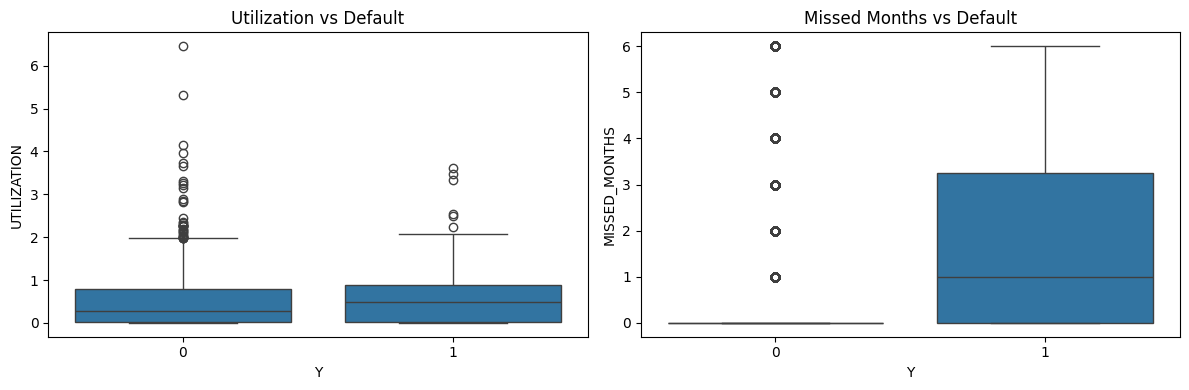

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Y", y="UTILIZATION", ax=axes[0])
axes[0].set_title("Utilization vs Default")

sns.boxplot(data=df, x="Y", y="MISSED_MONTHS", ax=axes[1])
axes[1].set_title("Missed Months vs Default")

plt.tight_layout()
plt.show()

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    brier_score_loss
)
import pandas as pd

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=100, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.08,
        max_leaf_nodes=15, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
        "Brier Score": brier_score_loss(y_test, prob)
    })

results = pd.DataFrame(results).set_index("Model")
print(results.round(4).sort_values("PR-AUC", ascending=False))


                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  \
Model                                                                       
Gradient Boosting      0.8023     0.6134  0.2869  0.3910   0.7175  0.4761   
Random Forest          0.7364     0.4238  0.5329  0.4721   0.7167  0.4751   
Decision Tree          0.8021     0.6106  0.2911  0.3943   0.7102  0.4565   
Logistic Regression    0.7916     0.6633  0.1175  0.1997   0.6727  0.4406   

                     Brier Score  
Model                             
Gradient Boosting         0.1476  
Random Forest             0.1995  
Decision Tree             0.1482  
Logistic Regression       0.1556  


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Use the already-fitted models and existing test data
threshold_results = []

for name in ["Random Forest", "Gradient Boosting"]:
    model = models[name]
    prob = model.predict_proba(X_test)[:, 1]

    for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
        pred = (prob >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, pred, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))


            Model  Threshold  Precision  Recall    F1
    Random Forest       0.20      0.229   0.977 0.371
    Random Forest       0.25      0.240   0.942 0.383
    Random Forest       0.30      0.270   0.869 0.411
    Random Forest       0.35      0.291   0.797 0.426
    Random Forest       0.40      0.320   0.717 0.443
    Random Forest       0.50      0.424   0.533 0.472
Gradient Boosting       0.20      0.396   0.579 0.470
Gradient Boosting       0.25      0.469   0.479 0.474
Gradient Boosting       0.30      0.510   0.426 0.464
Gradient Boosting       0.35      0.529   0.399 0.455
Gradient Boosting       0.40      0.566   0.377 0.452
Gradient Boosting       0.50      0.613   0.287 0.391


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

gb = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=15,
    random_state=42
)

gb.fit(X_train, y_train)

# Change from X_val to X_test
test_prob = gb.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.10, 0.51, 0.01)
scores = []

for t in thresholds:
    pred = (test_prob >= t).astype(int)

    scores.append({
        "threshold": t,
        "precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "f1": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_table = pd.DataFrame(scores)
best = threshold_table.loc[threshold_table["f1"].idxmax()]

print("Selected threshold:", round(best["threshold"], 2))
print(best)


Selected threshold: 0.26
threshold    0.260000
precision    0.481231
recall       0.471368
f1           0.476248
Name: 16, dtype: float64


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

test_prob = gb.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.26).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_prob), 4))
print("Brier Score:", round(brier_score_loss(y_test, test_prob), 4))

Confusion Matrix:
[[4998  843]
 [ 877  782]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      5841
           1       0.48      0.47      0.48      1659

    accuracy                           0.77      7500
   macro avg       0.67      0.66      0.66      7500
weighted avg       0.77      0.77      0.77      7500

ROC-AUC: 0.7175
PR-AUC: 0.4761
Brier Score: 0.1476


In [ ]:
from sklearn.metrics import brier_score_loss
import numpy as np

baseline_prob = np.full(len(y_test), y_train.mean())

print("Model Brier:",
      round(brier_score_loss(y_test, test_prob), 4))

print("Baseline Brier:",
      round(brier_score_loss(y_test, baseline_prob), 4))

Model Brier: 0.1476
Baseline Brier: 0.1723


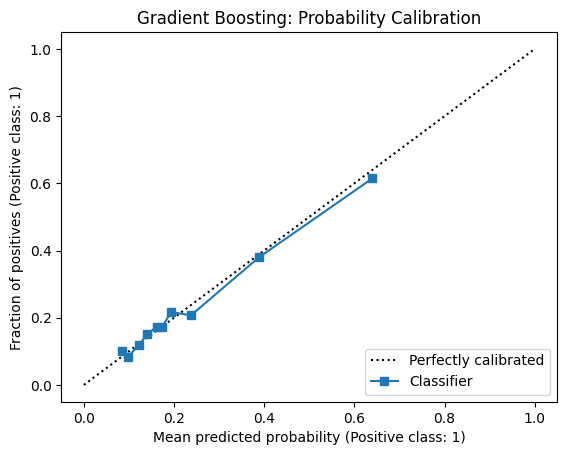

Model Brier Score: 0.1476
Baseline Brier Score: 0.1723


In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
import numpy as np

CalibrationDisplay.from_predictions(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.title("Gradient Boosting: Probability Calibration")
plt.show()

baseline_prob = np.full(len(y_test), np.mean(y_train))

print("Model Brier Score:",
      round(brier_score_loss(y_test, test_prob), 4))

print("Baseline Brier Score:",
      round(brier_score_loss(y_test, baseline_prob), 4))

In [ ]:
import pandas as pd
import numpy as np

risk_report = pd.DataFrame({
    "Actual_Default": np.asarray(y_test),
    "Predicted_Risk": test_prob
})

risk_report["Risk_Band"] = pd.cut(
    risk_report["Predicted_Risk"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1.01],
    labels=[
        "Low",
        "Moderate",
        "Elevated",
        "High",
        "Very High"
    ],
    include_lowest=True
)

summary = risk_report.groupby(
    "Risk_Band", observed=False
).agg(
    Borrowers=("Actual_Default", "size"),
    Avg_Predicted_Risk=("Predicted_Risk", "mean"),
    Actual_Default_Rate=("Actual_Default", "mean")
)

summary["Portfolio_Share"] = (
    summary["Borrowers"] / len(risk_report) * 100
)

summary["Avg_Predicted_Risk"] *= 100
summary["Actual_Default_Rate"] *= 100

print(summary.round(2))

           Borrowers  Avg_Predicted_Risk  Actual_Default_Rate  Portfolio_Share
Risk_Band                                                                     
Low             1405                9.00                 9.54            18.73
Moderate        3673               15.27                15.38            48.97
Elevated        1035               23.49                24.44            13.80
High             283               35.18                28.98             3.77
Very High       1104               57.75                56.61            14.72


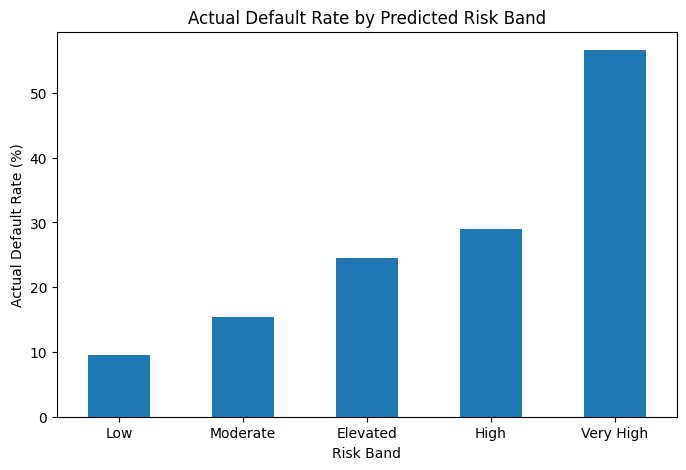

In [ ]:
summary["Actual_Default_Rate"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Actual Default Rate by Predicted Risk Band")
plt.xlabel("Risk Band")
plt.ylabel("Actual Default Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Instead of copying X_train, copy the corresponding rows from the full df
# so that we have access to all columns (including X6 and X12)
analysis_df = df.loc[X_train.index].copy()
analysis_df["DEFAULT"] = np.asarray(y_train)

# Map descriptive column names to the generic ones in the dataset
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

analysis_df["MISSED_MONTHS"] = (
    analysis_df[pay_cols] > 0
).sum(axis=1)

analysis_df["UTILIZATION"] = (
    analysis_df["X12"].clip(lower=0)
    / analysis_df["X1"].replace(0, np.nan)
)

print(analysis_df[
    ["DEFAULT", "MISSED_MONTHS", "UTILIZATION"]
].head())

       DEFAULT  MISSED_MONTHS  UTILIZATION
27350        1              0     0.005625
22029        0              0     0.915853
22166        0              1     0.002094
1880         0              0     0.999200
1319         0              0     0.069816


    Borrowers  Default_Rate
X6                         
-2       2066         12.73
-1       4256         16.92
 0      11047         12.75
 1       2797         34.36
 2       2009         69.34
 3        224         76.79
 4         52         67.31
 5         15         33.33
 6         10         60.00
 7          9         77.78
 8         15         46.67


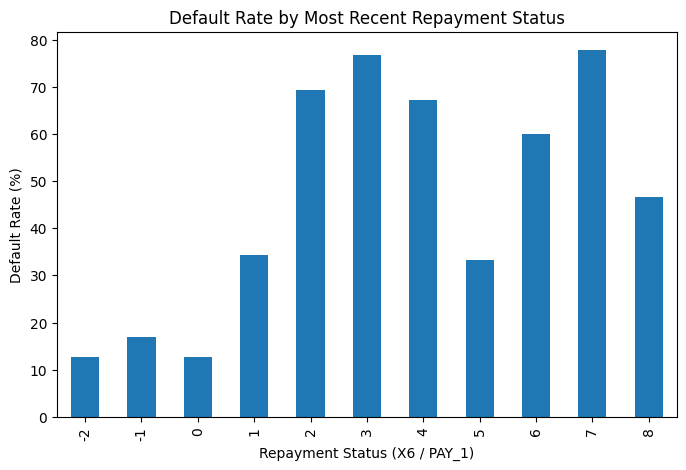

In [ ]:
delay_report = analysis_df.groupby("X6").agg(
    Borrowers=("DEFAULT", "size"),
    Default_Rate=("DEFAULT", "mean")
)

delay_report["Default_Rate"] *= 100

print(delay_report.round(2))

delay_report["Default_Rate"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("Repayment Status (X6 / PAY_1)")
plt.ylabel("Default Rate (%)")
plt.show()

               Borrowers  Default_Rate
MISSED_MONTHS                         
0                  14928         11.51
1                   3329         30.01
2                   1436         39.83
3                    866         50.69
4                    725         58.34
5                    222         60.36
6                    994         69.62


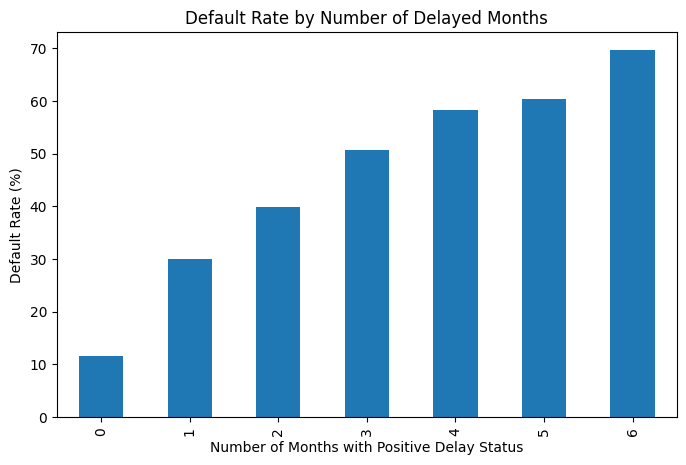

In [ ]:
delay_report = analysis_df.groupby("MISSED_MONTHS").agg(
    Borrowers=("DEFAULT", "size"),
    Default_Rate=("DEFAULT", "mean")
)

delay_report["Default_Rate"] *= 100

print(delay_report.round(2))

delay_report["Default_Rate"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Default Rate by Number of Delayed Months")
plt.xlabel("Number of Months with Positive Delay Status")
plt.ylabel("Default Rate (%)")
plt.show()

In [ ]:
analysis_df["UTILIZATION_BAND"] = pd.cut(
    analysis_df["UTILIZATION"],
    bins=[-0.01, 0.10, 0.30, 0.60, 1.00, np.inf],
    labels=[
        "0–10%", "10–30%", "30–60%",
        "60–100%", "Above 100%"
    ]
)

util_report = analysis_df.groupby(
    "UTILIZATION_BAND", observed=False
).agg(
    Borrowers=("DEFAULT", "size"),
    Default_Rate=("DEFAULT", "mean")
)

util_report["Default_Rate"] *= 100

print(util_report.round(2))

                  Borrowers  Default_Rate
UTILIZATION_BAND                         
0–10%                  8466         18.50
10–30%                 2638         16.87
30–60%                 3241         23.94
60–100%                6567         25.93
Above 100%             1588         30.67


  Feature  Importance     Std
1      X7      0.1242  0.0060
0      X1      0.0256  0.0045
5     X11      0.0192  0.0036
4     X10      0.0103  0.0022
3      X9      0.0096  0.0018
2      X8      0.0087  0.0027


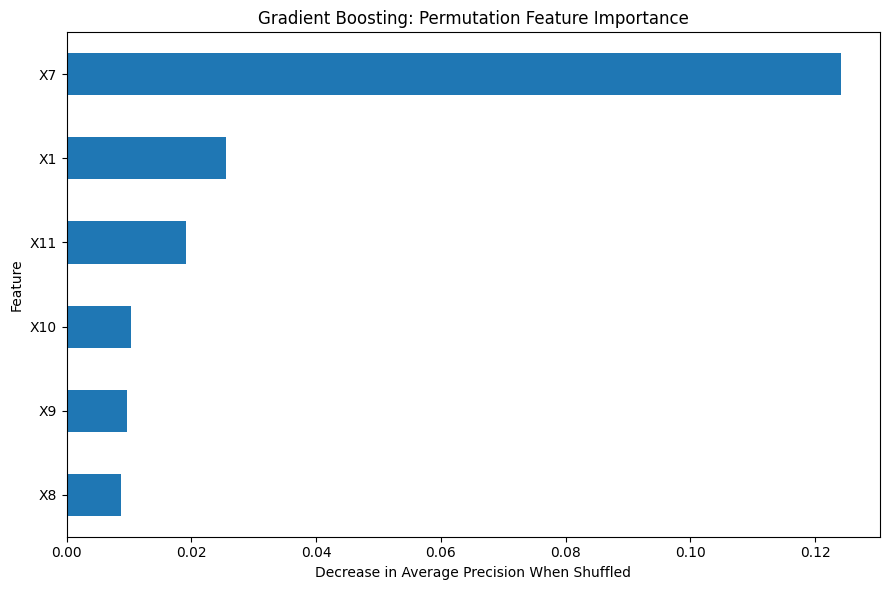

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Compute permutation importance using the test set (X_test, y_test) as X_val/y_val is not defined
importance = permutation_importance(
    gb,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print(importance_df.head(15).round(4))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 6),
    legend=False
)

plt.title("Gradient Boosting: Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision When Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score,
    average_precision_score, brier_score_loss
)

# Reserve a fresh holdout
dev_df, final_df = train_test_split(
    df, test_size=0.20, random_state=2026,
    stratify=df["Y"]
)

# Keep the same predictors used by your existing model
features = X_train.columns.tolist()

X_dev = dev_df[features]
y_dev = dev_df["Y"]

X_final = final_df[features]
y_final = final_df["Y"]

# Train on development data
final_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=15,
    random_state=42
)

final_model.fit(X_dev, y_dev)
final_prob = final_model.predict_proba(X_final)[:, 1]

# Use your previously selected threshold
threshold = 0.26
final_pred = (final_prob >= threshold).astype(int)

print(classification_report(y_final, final_pred))
print("ROC-AUC:", round(roc_auc_score(y_final, final_prob), 4))
print("PR-AUC:", round(average_precision_score(y_final, final_prob), 4))
print("Brier:", round(brier_score_loss(y_final, final_prob), 4))

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4673
           1       0.50      0.48      0.49      1327

    accuracy                           0.78      6000
   macro avg       0.67      0.67      0.67      6000
weighted avg       0.77      0.78      0.78      6000

ROC-AUC: 0.7397
PR-AUC: 0.4884
Brier: 0.1445


In [50]:
import pandas as pd
import numpy as np

report = pd.DataFrame({
    "Actual_Default": np.asarray(y_final),
    "Predicted_Risk": final_prob
})

report["Risk_Band"] = pd.cut(
    report["Predicted_Risk"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1.01],
    labels=["Low", "Moderate", "Elevated", "High", "Very High"],
    include_lowest=True
)

portfolio = report.groupby(
    "Risk_Band", observed=False
).agg(
    Borrowers=("Actual_Default", "size"),
    Mean_Predicted_Risk=("Predicted_Risk", "mean"),
    Actual_Default_Rate=("Actual_Default", "mean")
)

portfolio["Portfolio_Share_%"] = (
    portfolio["Borrowers"] / len(report) * 100
)
portfolio["Mean_Predicted_Risk"] *= 100
portfolio["Actual_Default_Rate"] *= 100

print(portfolio.round(2))
portfolio.to_csv("portfolio_risk_report.csv")

           Borrowers  Mean_Predicted_Risk  Actual_Default_Rate  \
Risk_Band                                                        
Low              509                 8.90                 7.86   
Moderate        3520                14.64                13.78   
Elevated         848                23.53                25.00   
High             257                34.01                33.46   
Very High        866                55.88                58.20   

           Portfolio_Share_%  
Risk_Band                     
Low                     8.48  
Moderate               58.67  
Elevated               14.13  
High                    4.28  
Very High              14.43  


In [51]:
from google.colab import files
files.download("/content/portfolio_risk_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
readme = """# Credit Default Risk & Early Warning System

## Overview
A Python-based credit risk analytics project that estimates
credit-card default risk, segments borrowers into risk bands,
and explores repayment-related warning indicators.

## Dataset
UCI Default of Credit Card Clients:
https://archive.ics.uci.edu/dataset/350/default+credit+card+clients

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## Methods
- Exploratory data analysis
- Repayment-delay and credit-utilization analysis
- Logistic Regression, Decision Tree, Random Forest,
  and Gradient Boosting comparison
- Precision, recall, F1-score, ROC-AUC, PR-AUC and Brier score
- Threshold evaluation and risk segmentation
- Permutation feature importance

## Key Findings
Repeated repayment delays were associated with higher observed
default rates. Recent repayment status was also informative,
while credit utilization provided additional, less consistent
risk information.

## Limitations
Historical data may not represent current borrower behaviour.
Associations do not establish causality, and model outputs
require further validation before any operational use.

## Disclaimer
Educational portfolio project; not intended for actual lending decisions."""

with open("/content/README.md", "w") as f:
    f.write(readme)

print("README.md created")

README.md created


In [55]:
files.download("/content/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>